In [2]:
# calling libraries

from datetime import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy.stats as stats

In [3]:
with open('/content/DoB.txt', 'r') as f:
    dob = f.read()

# pre-processing the data

dob_list = dob.split('\n')
# print(dob_list)
curr_date = datetime.now()
# print(curr_date)
curr_year = curr_date.year
# print(curr_year)

# ages_list=[]
ages = []

# rounding birth years of the dataset:
for dates in range(len(dob_list)):
    date_mm_yy = dob_list[dates].split('-')
    if len(date_mm_yy) == 3:
        year = date_mm_yy[2]
    if len(year) == 2:
        year ='19' + year  #19XX years
    ages.append(curr_year - int(year))

# print(dob_list)
age_dic = {'Birth_dates': dob_list, 'Ages': ages}
df_ages_all = pd.DataFrame(age_dic)
df_ages_all

,Birth_dates,Ages
0,16-Sep-24,99
1,16-Sep-24,99
2,16-Sep-24,99
3,16-Sep-24,99
4,16-Sep-24,99
...,...,...
460713,29-Dec-89,34
460714,29-Dec-89,34
460715,29-Dec-89,34
460716,29-Dec-89,34


In [4]:
# ranging ages from 1 to 99
df_ages_all_1_99 = df_ages_all[df_ages_all['Ages'].between(1, 99, inclusive=True)]

<ipython-input-4-1b3e983b665f>:2: FutureWarning: Boolean inputs to the `inclusive` argument are deprecated in favour of `both` or `neither`.
  df_ages_all_1_99 = df_ages_all[df_ages_all['Ages'].between(1, 99, inclusive=True)]


In [5]:
# verifying age range:
print("Min Age:", df_ages_all_1_99["Ages"].min())
print("Max Age", df_ages_all_1_99["Ages"].max())

Min Age: 24
Max Age 99


In [6]:
# seperating the 1st and Last digit:

x = df_ages_all_1_99['Ages']

# % -> modulus
# // -> divides with integral result (discard remainder)

df_ages_all_1_99['first_digit'] = (x % 100) // 10
df_ages_all_1_99['last_digit'] = (x % 10)
df_ages_all_1_99

<ipython-input-6-cc87e551f9ff>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ages_all_1_99['first_digit'] = (x % 100) // 10
<ipython-input-6-cc87e551f9ff>:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ages_all_1_99['last_digit'] = (x % 10)


,Birth_dates,Ages,first_digit,last_digit
0,16-Sep-24,99,9,9
1,16-Sep-24,99,9,9
2,16-Sep-24,99,9,9
3,16-Sep-24,99,9,9
4,16-Sep-24,99,9,9
...,...,...,...,...
460713,29-Dec-89,34,3,4
460714,29-Dec-89,34,3,4
460715,29-Dec-89,34,3,4
460716,29-Dec-89,34,3,4


# **Distribution of the age**

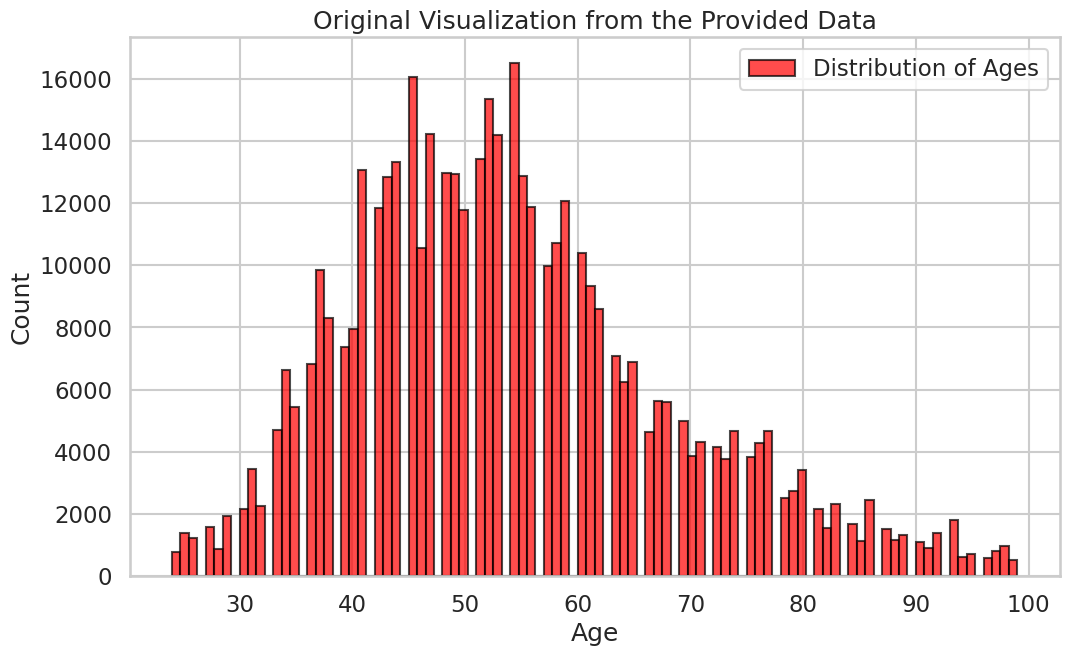

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns  # seaborn helps improve the visual aesthetics
# Setting up style and context using seaborn
sns.set_style("whitegrid")
sns.set_context("talk")  # 'talk' context is for presentations

# Creating  the histogram
plt.figure(figsize=(12, 7))

# Plotting histogram with slight transparency
plt.hist(df_ages_all_1_99['Ages'], bins=100, color="red", alpha=0.7, edgecolor="black")

# Adding labels, title, legend, and other aesthetics
plt.title("Original Visualization from the Provided Data")
plt.xlabel("Age")
plt.ylabel("Count")
plt.legend(labels=["Distribution of Ages"], loc="upper right")

# Displaying the plot
plt.show()


# **Distribution of the 1st age Digit**

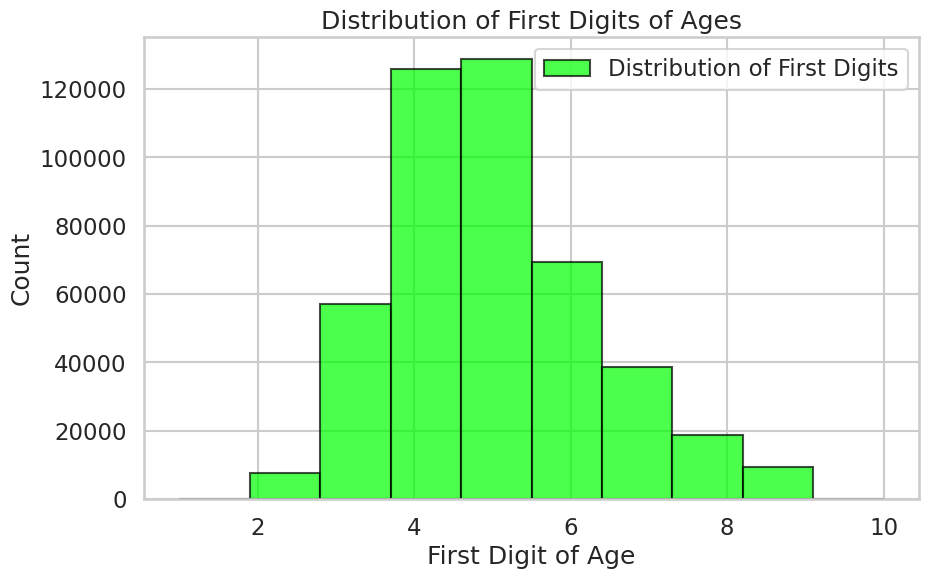

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns  # seaborn enhances the visual aesthetics

# Setting up style and context using seaborn
sns.set_style("whitegrid")
sns.set_context("talk")  # 'talk' context is suitable for presentations

# Creating the histogram
plt.figure(figsize=(10, 6))

# Plotting the histogram with slight transparency
plt.hist(df_ages_all_1_99['first_digit'], bins=10, range=(1,10), color='lime', alpha=0.7, edgecolor="black")

# Adding labels, legend, and other aesthetics
plt.title("Distribution of First Digits of Ages")
plt.xlabel("First Digit of Age")
plt.ylabel("Count")
plt.legend(labels=["Distribution of First Digits"], loc="upper right")

# Displaying the plot
plt.show()


# **Distribution of the Last age Digit**

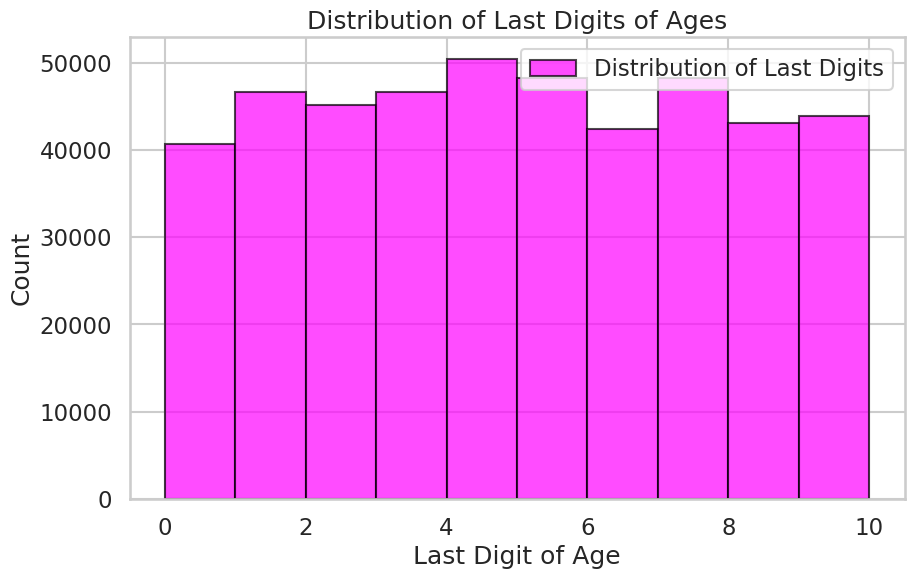

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns  # seaborn enhances the visual aesthetics

# Set up style and context using seaborn
sns.set_style("whitegrid")
sns.set_context("talk")  # 'talk' context is suitable for presentations

# Create the histogram
plt.figure(figsize=(10, 6))

# Plot the histogram with 10 bins for the last digits (0-9)
plt.hist(df_ages_all_1_99['last_digit'], bins=10, range=(0,10), color='magenta', alpha=0.7, edgecolor="black")

# Add labels, legend, and other aesthetics
plt.title("Distribution of Last Digits of Ages")
plt.xlabel("Last Digit of Age")
plt.ylabel("Count")
plt.legend(labels=["Distribution of Last Digits"], loc="upper right")

# Display the plot
plt.show()
